In [4]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.stats.multitest as sm 
import seaborn as sns

In [6]:
df = pd.read_csv('../../raw_data/Glycosphingolipid_analysis/Deep-surface_GSLs_zscores.csv')
df['patient_id'] = list(df['id'].str.split('_', expand = True)[1].str.split('Deep', expand = True)[0].str.split('Surface', expand = True)[0])
df['type'] = np.where(df['id'].str.contains('Deep', case=False, na=False), 'Deep', 'Surface')
categories = ['2.16', 'GA2', '2.67', 'Gb3', 'GM3', '3.23', 'GM2','3.57', '3.61', 'GA1', '4.03', 'GM1a', 'GD3', 'GM1b', 'GD2', 'GD1a','5.24', '5.33', '5.45', 'GD1b', '5.99', 'GT1b', '6.84', '6.99', 'GQ1b','8.07']

deep = df[df['type']=='Deep']
deep.columns = [col + '_deep' for col in deep.columns]
deep.rename(columns = {'id_deep':'id','group_deep':'group','patient_id_deep':'patient_id','type_deep':'type'}, inplace = True)

surface = df[df['type']=='Surface']
surface.columns = [col + '_surface' for col in surface.columns]
surface.drop(columns = ['group_surface', 'id_surface', 'type_surface', 'id_surface'], inplace = True)
surface.rename(columns = {'patient_id_surface':'patient_id'}, inplace = True)
surface

paired = deep.merge(surface, left_on = 'patient_id', right_on = 'patient_id', how = 'inner')
paired = paired[paired['group']=='PD']
list_tests = []
for comp in categories:
    paired_filtered = paired[[col for col in paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)

        if comp == categories[0]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

/tmp/ipykernel_428185/3626902587.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  deep.rename(columns = {'id_deep':'id','group_deep':'group','patient_id_deep':'patient_id','type_deep':'type'}, inplace = True)
/tmp/ipykernel_428185/3626902587.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  surface.drop(columns = ['group_surface', 'id_surface', 'type_surface', 'id_surface'], inplace = True)
/tmp/ipykernel_428185/3626902587.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/

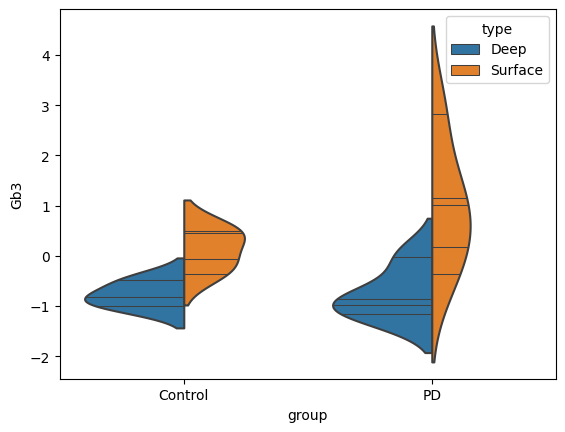

In [7]:


for cat in list(sig.index):
    sns.violinplot(x = df["group"], y = df[cat], hue = df["type"], split = True, inner="stick")
    #sns.swarmplot(x = df["group"], y = df[cat], hue = df["type"])
    plt.show()